# Validate against buoy observations

Compare the **offshore hindcast** (closest goal node) and the **spectral
metamodel** of each offshore source (water level from `forcing.water_level`),
to buoy records. The dynamic runs are
compared in `09_Validate_Linear_Summation.ipynb`.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Offshore sources (`07a`, `07b`)
3. Observations GeoJSON — `03_Generate_Observations_Configuration.ipynb` → `inputs/Observations/<Case>_observations.json`
4. Processed hourly buoy files in `inputs/Observations/processed/` (notebook 03).

The reconstructions are read from the cache (`tmp/reconstruct/`); fill it
beforehand on the compute node for long periods (a script calling
`mm.reconstruct` with the same arguments). Anything missing is computed here.

Comparisons request `metamodel.validation.metrics_variables` (`hs`, `tp`, `tm01`,
`dir`, `spr`). `tm01` (m0/m1) comes from the summed spectrum of the reconstruction,
not from a prediction; the offshore hindcasts have none, so it is compared for the
metamodel only. Variables missing from the buoy file or a model are skipped.

The buoys validated are
the `ok` buoy sites of `outputs/output_sites_{model}.csv` (notebook 03) that have
`hs` in `period`; buoys outside the mesh or that can dry have no model output.

In [1]:
import matplotlib.pyplot as plt
from utils import metamodel as mm
from utils import onshore_sites as obs
from utils import validation as val

## Configuration

The modelled buoys of the observations GeoJSON (`instrument_id` keys that are `ok`
output sites, notebook 03). Site labels are `buoy_{instrument_id}`. Processed hourly files (`hs`, `tp`, `dir`,
`spr` where measured) are built in notebook 03.

In [2]:
period = slice("2014-10-23", "2018-12-31")  # within the water-level forcing
offshore_names = ["WHACS", "WHACS_cal"]  # offshore_waves entries
mda_n = 800  # must match a fitted mda_candidates entry
mm_set = "buoys"  # metamodel set (metamodel.sets) fitted on the buoys
primary = "Metamodel WHACS_cal"  # estimate of the GUI summary figures

# Modelled buoys (ok output sites, notebook 03); processed hourly files
# (hs, tp, tm01, dir, spr) in inputs/Observations/processed/<instrument_id>.nc
sites = obs.list_snapwave_buoy_sites()

requested_variables = (
    val.METRICS_VARIABLES
)  # metamodel.validation.metrics_variables (tm01: reconstruction only)

print("Observations JSON:", obs.geojson_path())
print(f"period         : {period}")
print(f"offshore       : {offshore_names}")
print(f"mda_n          : {mda_n}")
print(f"metamodel      : {mm_set}")
print(f"sites          : {sites}")
print(f"requested vars : {requested_variables}")

Observations JSON: /lustre/geocean/WORK/users/javiert/projects/HyGloW/Samoa/inputs/Observations/Samoa_observations.json
period         : slice('2014-10-23', '2018-12-31', None)
offshore       : ['WHACS', 'WHACS_cal']
mda_n          : 800
metamodel      : buoys
sites          : ['buoy_Aunuu_1', 'buoy_Aunuu_2', 'buoy_King_Poloa']
requested vars : ['hs', 'tp', 'tm01', 'dir', 'spr']


## 1 · Check models

In [3]:
mm.require_models(mm_set, mda_n)

## 2 · Buoy observations

The processed hourly file of each buoy (notebook 03) in `period`, on
`(time, sites)` with CF-style attributes and the site metadata; buoys without
`hs` in `period` are skipped.

In [4]:
buoy = val.load_buoy_observations(period, sites, variables=requested_variables)
skipped = sorted(set(sites) - set(buoy.sites.values))
sites = list(buoy.sites.values)
print(f"{len(sites)} buoys with hs in {period}; skipped (no data): {skipped}")
buoy

2 buoys with hs in slice('2014-10-23', '2018-12-31', None); skipped (no data): ['buoy_King_Poloa']


<xarray.Dataset> Size: 1MB
Dimensions:             (time: 26077, sites: 2)
Coordinates:
  * time                (time) datetime64[ns] 209kB 2014-10-23T22:00:00 ... 2...
  * sites               (sites) <U12 96B 'buoy_Aunuu_1' 'buoy_Aunuu_2'
    site_source         (sites) object 16B 'buoy' 'buoy'
    site_label          (sites) object 16B 'waves' 'waves'
    site_mesh_depth     (sites) float64 16B 74.48 55.78
    site_nominal_depth  (sites) float64 16B 79.0 55.0
    site_longitude      (sites) float64 16B -170.5 -170.5
    site_latitude       (sites) float64 16B -14.27 -14.27
Data variables:
    hs                  (time, sites) float32 209kB 1.697 nan ... nan 1.944
    tp                  (time, sites) float32 209kB 10.53 nan ... nan 9.091
    tm01                (time, sites) float32 209kB 6.269 nan ... nan 7.292
    dir                 (time, sites) float32 209kB 130.3 nan ... nan 42.35
    spr                 (time, sites) float32 209kB 49.59 nan 50.9 ... nan 70.12

## 3 · Metamodel reconstructions and closest-goal offshore hindcast

The spectral metamodel for every offshore source (read from the cache), and
the bulk offshore hindcast at each buoy's **closest goal node**.

In [5]:
# Resources for the reconstructions below (at most 75% of this machine).
# Edit res if wanted (res.workers = ...).
res = mm.reconstruction_resources(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=True,
    offshore_name=offshore_names[0],
    wl="forcing",
    save_spectra=False,
)

Machine   48 cores, 440 GiB free of 503 GiB, no GPU -> at most 36 cores, 330 GiB (75%)
Request   buoys n=800 spectral (64 contributions/site), slice('2014-10-23', '2018-12-31', None): 0 of 153 site-months to compute, in 0 month(s)
Proposed  device cpu, 36 threads (GP + PCA), 36 workers (spectral sum), 1 month(s) x every site per call, 330 GiB
Spectra   not saved (save_spectra=True to keep them): ~0.0 GB on disk for these site-months, 7880 GB free
Edit the fields if wanted (res.workers = ...), then reconstruct(..., resources=res).


In [6]:
metamodel = {
    f"Metamodel {name}": mm.reconstruct(
        period,
        mda_n,
        metamodel=mm_set,
        spectral=True,
        offshore_name=name,
        wl="forcing",
        save_spectra=False,
        resources=res,
    )
    for name in offshore_names
}

offshore_hindcast, closest_goals = val.load_offshore_hindcast_at_buoys(
    period,
    sites,
    offshore_names=offshore_names,
    variables=requested_variables,
)

estimates = {**offshore_hindcast, **metamodel}

variables = val.resolve_comparison_variables(  # the hindcasts lack tm01: compare_all pairs each estimate on its own
    buoy,
    *metamodel.values(),
    variables=requested_variables,
)
print(f"Comparing: {variables}")

Comparing: ['hs', 'tp', 'tm01', 'dir', 'spr']


## 4 · Metrics vs buoy

In [7]:
results = val.compare_all(
    buoy,
    estimates,
    variables=variables,
    reference_label="Buoy",
)

summary = val.metrics_summary(results)
summary

,group,site_source,site_label,variable,label,n,bias,rmse,rrmse,si,r,r2,model
0,buoy_Aunuu_1,buoy,waves,hs,Hs,20892,-0.135451,0.239547,0.112789,0.090436,0.922809,0.781074,WHACS (closest goal)
1,buoy_Aunuu_1,buoy,waves,tp,Tp,20892,1.089012,2.733187,0.253255,0.227000,0.480196,-0.361770,WHACS (closest goal)
2,buoy_Aunuu_1,buoy,waves,dir,Dir,20892,0.527463,31.299314,NaN,NaN,NaN,0.600274,WHACS (closest goal)
3,buoy_Aunuu_1,buoy,waves,spr,Spr,20892,1.332600,5.855600,0.102691,0.098575,0.851210,0.636876,WHACS (closest goal)
4,buoy_Aunuu_2,buoy,waves,hs,Hs,5185,-0.118225,0.190449,0.089315,0.067728,0.963856,0.884218,WHACS (closest goal)
5,buoy_Aunuu_2,buoy,waves,tp,Tp,5185,1.221773,3.058768,0.282773,0.252734,0.421266,-0.534365,WHACS (closest goal)
6,buoy_Aunuu_2,buoy,waves,dir,Dir,5185,3.689162,21.601473,NaN,NaN,NaN,0.700300,WHACS (closest goal)
7,buoy_Aunuu_2,buoy,waves,spr,Spr,5185,0.996588,4.955483,0.093218,0.090353,0.863856,0.593574,WHACS (closest goal)
8,buoy_Aunuu_1,buoy,waves,hs,Hs,20892,0.065763,0.235797,0.111023,0.103649,0.906685,0.787875,WHACS_cal (closest goal)
9,buoy_Aunuu_1,buoy,waves,tp,Tp,20892,1.089012,2.733187,0.253255,0.227000,0.480196,-0.361770,WHACS_cal (closest goal)


Median over the buoys, per estimate and variable:

In [8]:
summary.groupby(["label", "model"])[["n", "bias", "rmse", "r2"]].median().round(3)

n   bias    rmse     r2
label model                                                  
Dir   Metamodel WHACS           13038.5  5.205  28.999  0.574
      Metamodel WHACS_cal       13038.5  4.116  32.081  0.474
      WHACS (closest goal)      13038.5  2.108  26.450  0.650
      WHACS_cal (closest goal)  13038.5  2.108  26.450  0.650
Hs    Metamodel WHACS           13038.5 -0.149   0.227  0.816
      Metamodel WHACS_cal       13038.5  0.010   0.202  0.853
      WHACS (closest goal)      13038.5 -0.127   0.215  0.833
      WHACS_cal (closest goal)  13038.5  0.057   0.215  0.834
Spr   Metamodel WHACS           13038.5 -4.988   7.858  0.158
      Metamodel WHACS_cal       13038.5 -4.101   7.717  0.184
      WHACS (closest goal)      13038.5  1.165   5.406  0.615
      WHACS_cal (closest goal)  13038.5  1.165   5.406  0.615
Tm01  Metamodel WHACS           13038.5  0.513   0.872  0.019
      Metamodel WHACS_cal       13038.5  0.674   0.967 -0.206
Tp    Metamodel WHACS           13038.5 -0.876   2.522 -0.098
      Metamodel WHACS_cal       13038.5 -0.537   2.325  0.067
      WHACS (closest goal)      13038.5  1.155   2.896 -0.448
      WHACS_cal (closest goal)  13038.5  1.155   2.896 -0.448

## 4b · Save summary

In [9]:
# `period` is a slice here (not a single string) — derive a clean,
# filesystem-safe label from it once; the summary PNG save cell reuses it.
period_label = period if isinstance(period, str) else f"{period.start}-{period.stop}"

summary_out = summary.copy()
summary_out.insert(0, "period", period_label)
summary_out.insert(1, "metamodel", mm_set)
summary_out.insert(2, "mda_candidate", mda_n)

out_path = val.buoy_validation_path("onshore", period_label)
out_path.parent.mkdir(parents=True, exist_ok=True)
summary_out.to_csv(out_path, index=False)
print(f"Wrote {out_path}")

Wrote /lustre/geocean/WORK/users/javiert/projects/HyGloW/Samoa/outputs/buoy_validation/onshore_summary_2014-10-23-2018-12-31.csv


## 5 · Scatter plots

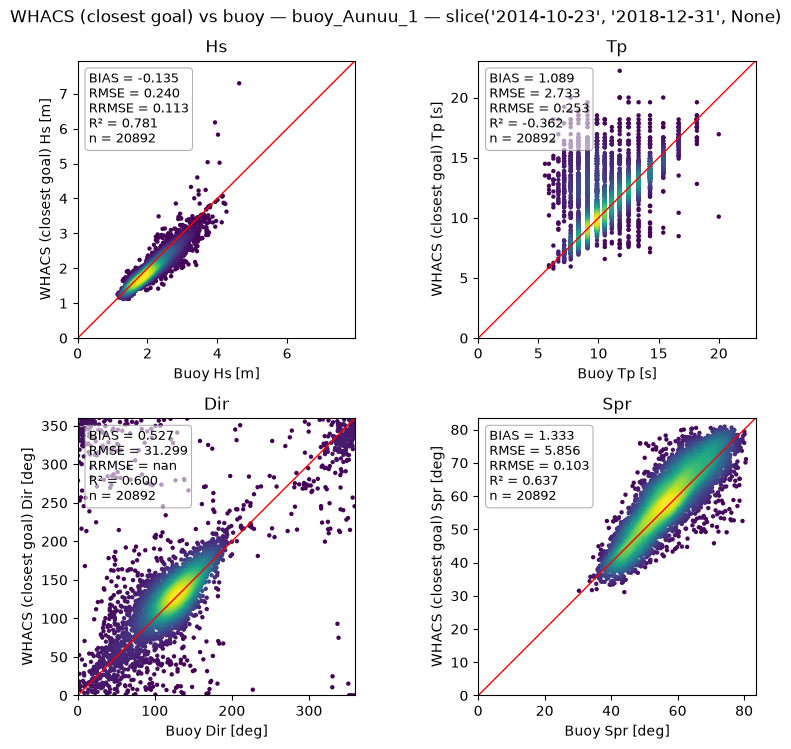

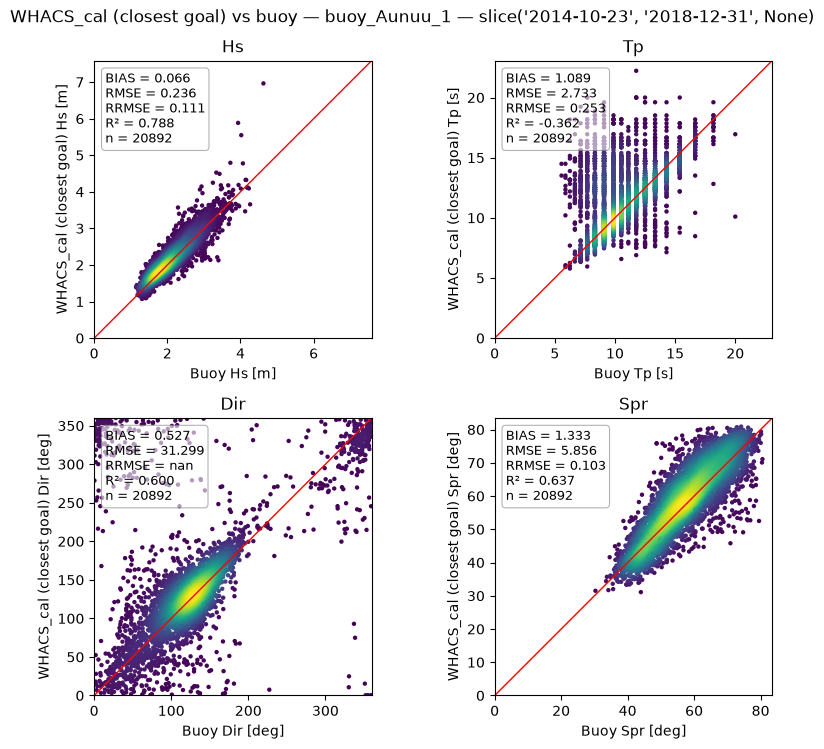

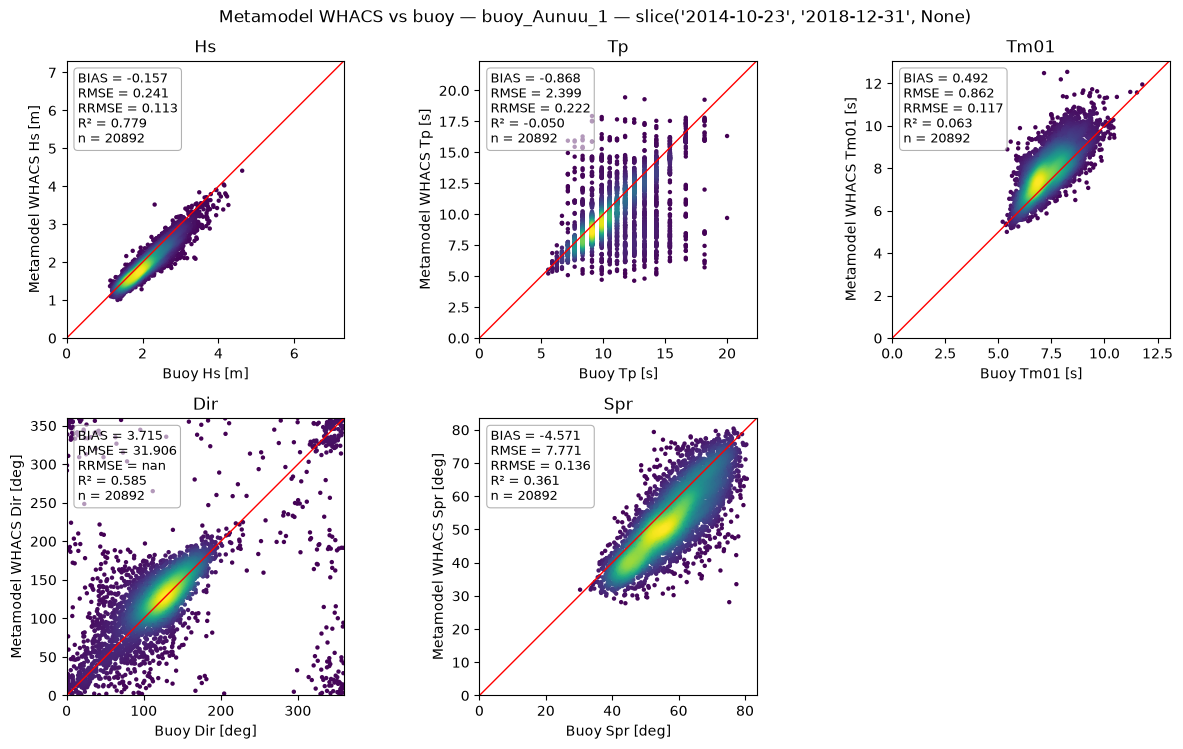

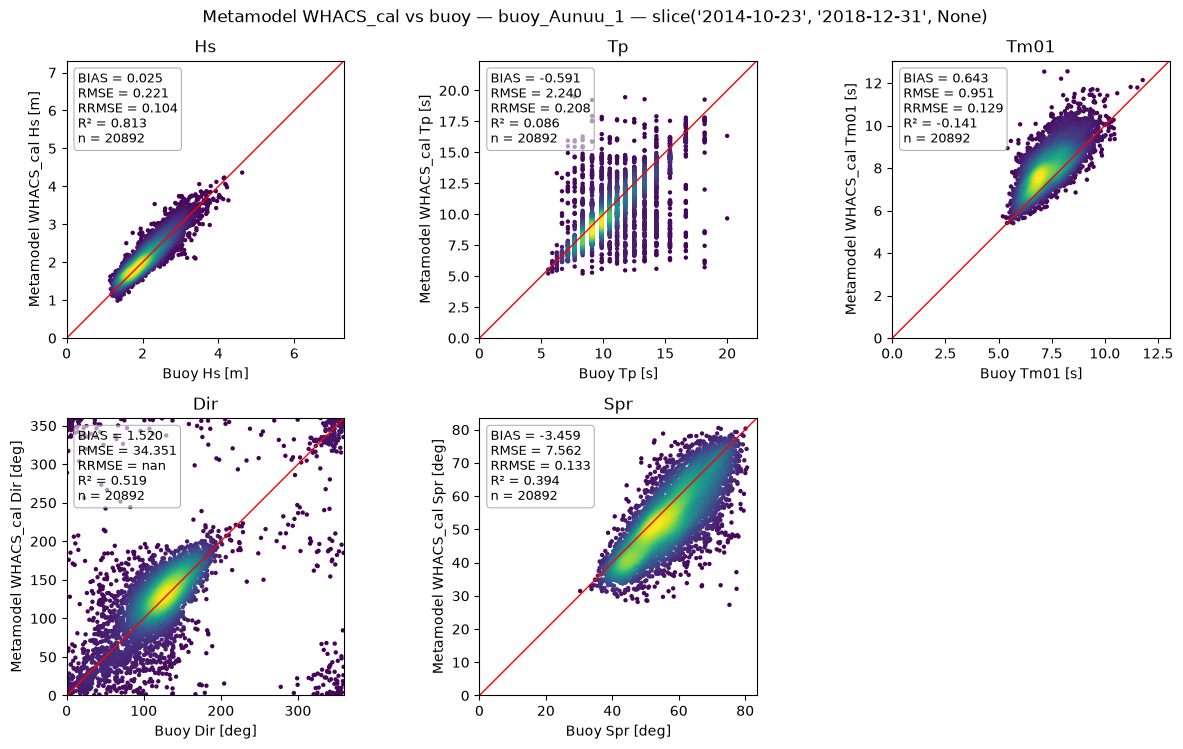

In [10]:
for site in sites:
    for name, result in results.items():
        result.plot_scatter(site, variables)
        plt.suptitle(f"{name} vs buoy — {site} — {period}")
        plt.show()
    break

## 6 · Time series

Line plots of buoy observations vs each model over the validation period (direction as scatter).

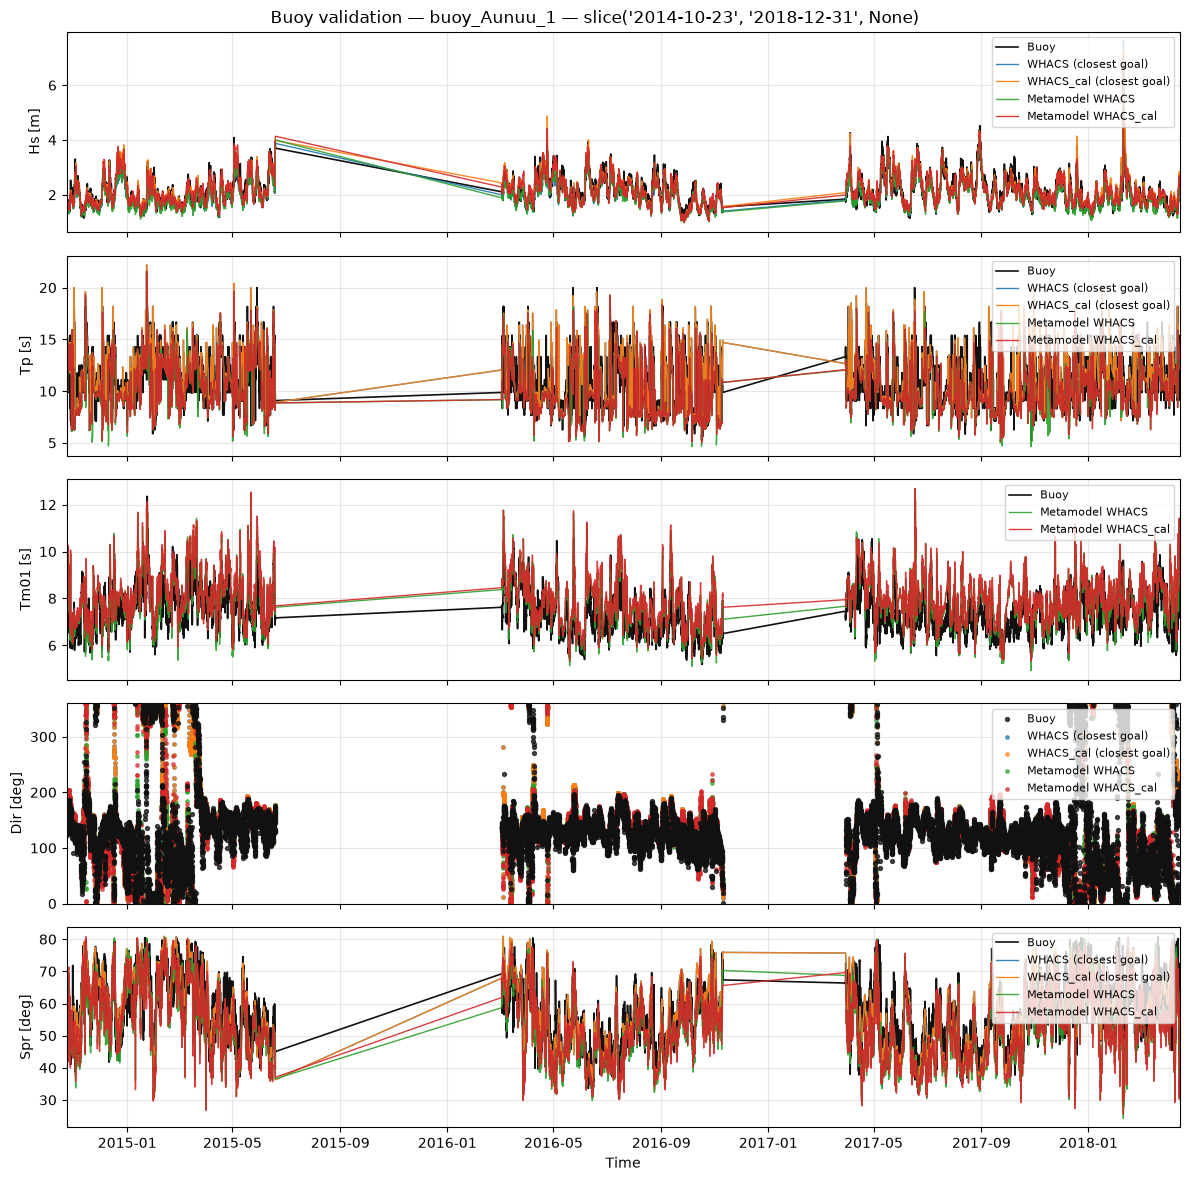

In [11]:
for site in sites:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=variables)
    plt.suptitle(f"Buoy validation — {site} — {period}")
    plt.show()
    break

## 7 · Save per-buoy summary PNG (GUI)

Density scatter (top row, buoy vs. the `primary` estimate) + one wide Hs/Tp time series (bottom row, cropped to when the buoy actually has data) — one combined PNG per buoy, shown as-is in the GUI's Buoy Validation tab when you click that buoy's star on the map.

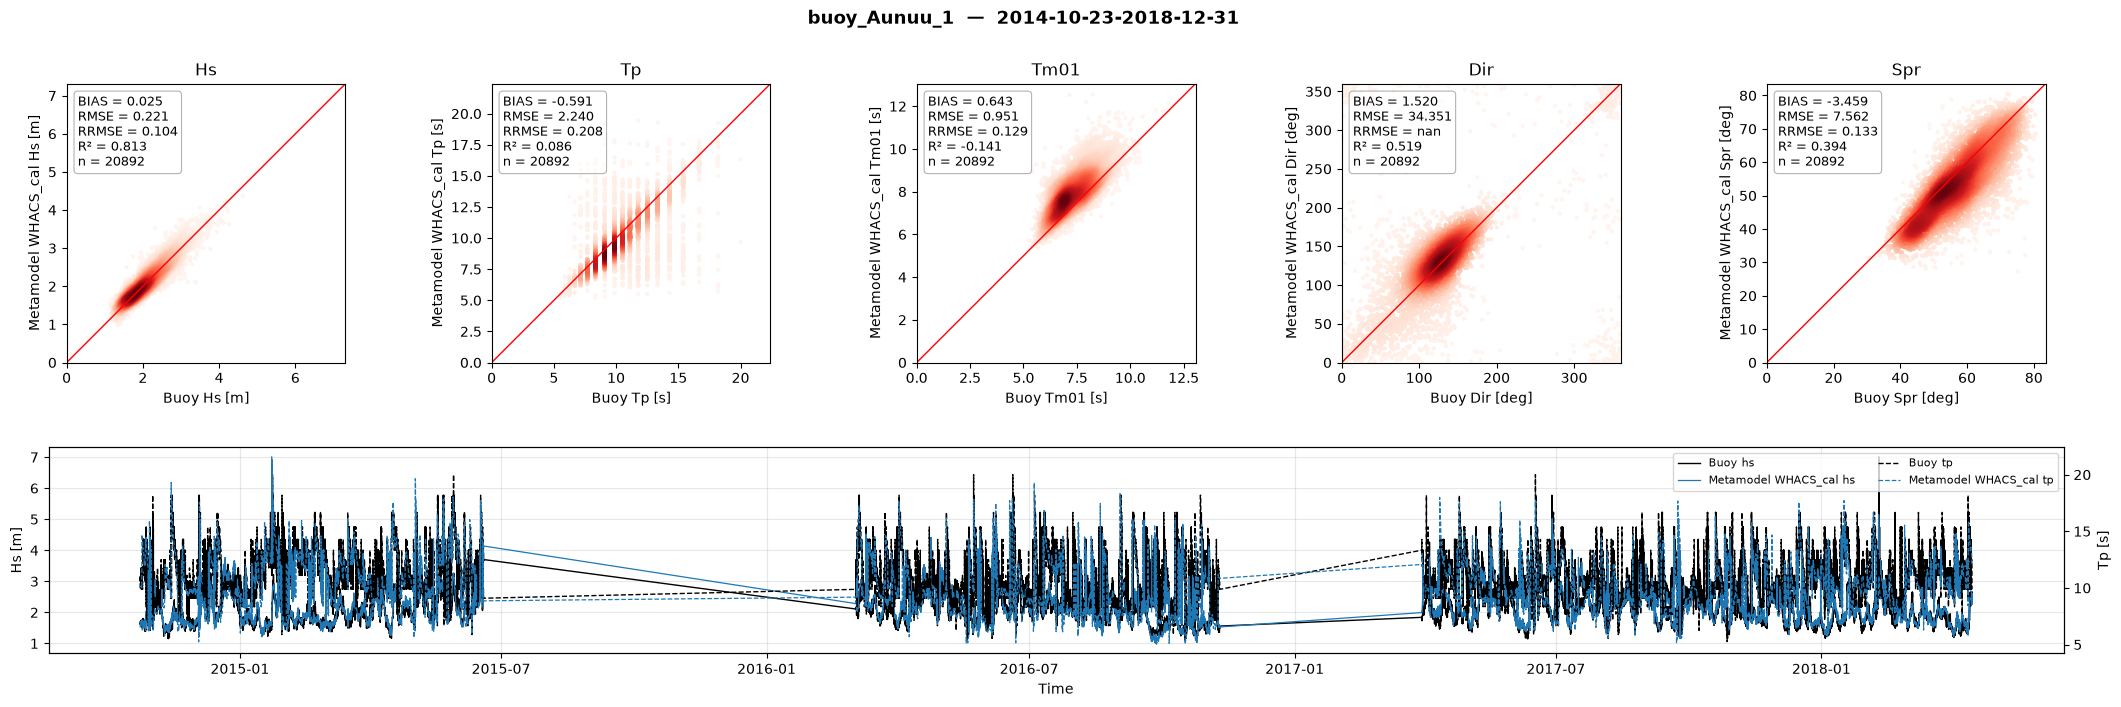

saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Samoa/outputs/buoy_validation/figures/buoy_Aunuu_1.png


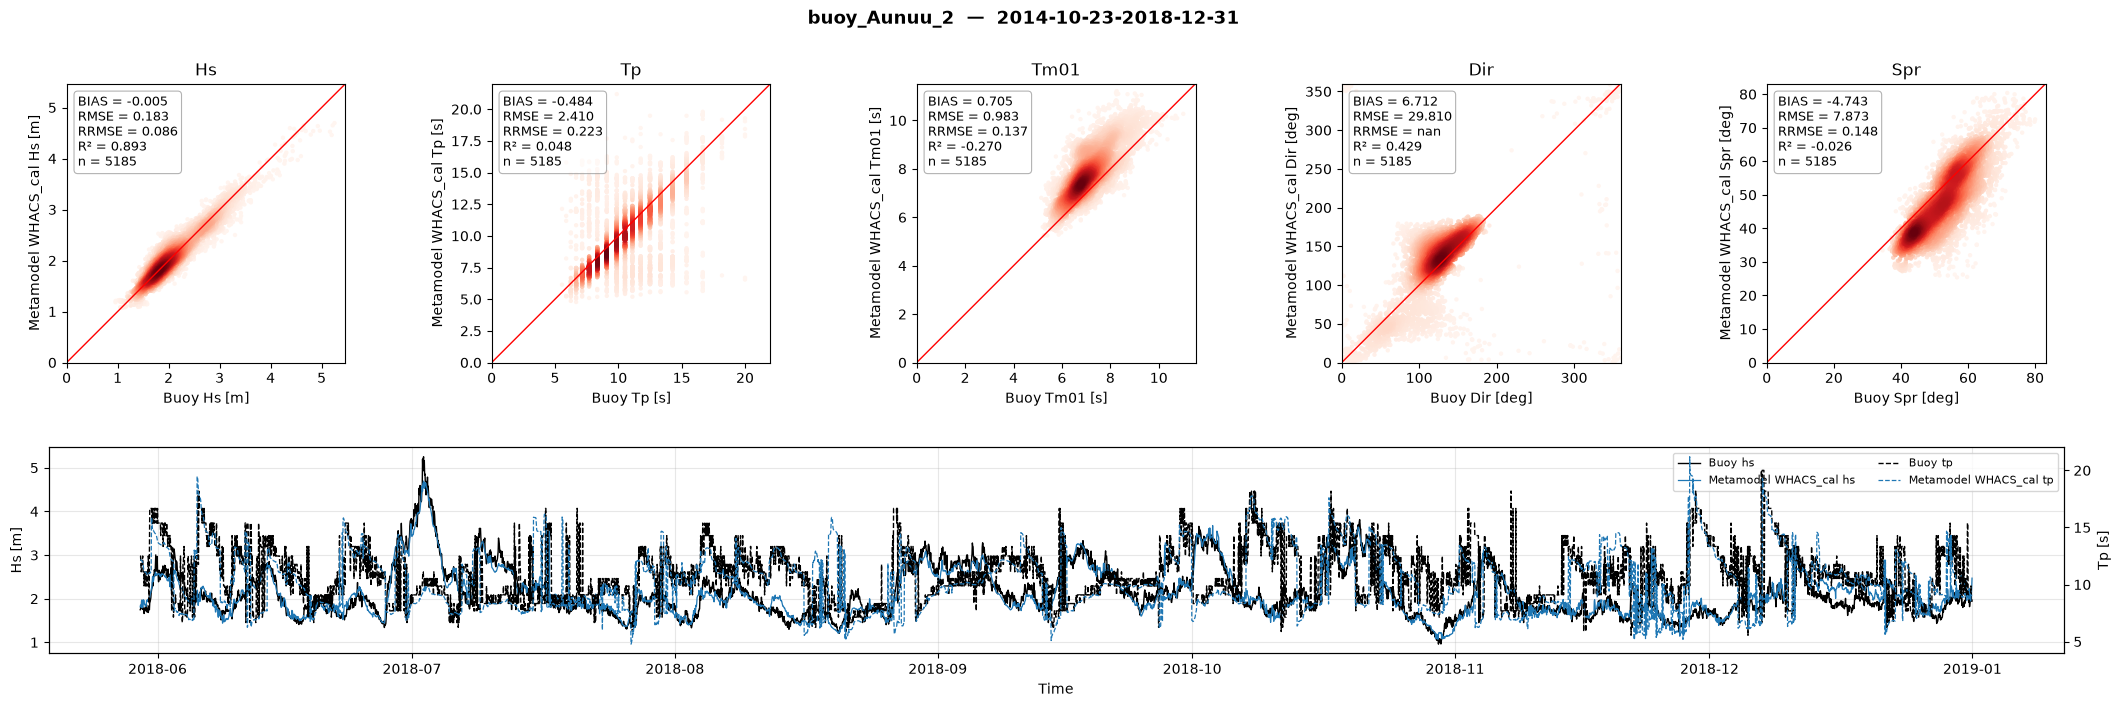

saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Samoa/outputs/buoy_validation/figures/buoy_Aunuu_2.png


In [12]:
for site in sites:
    fig = val.plot_buoy_summary(
        buoy,
        estimates[primary],
        site,
        variables=variables,
        reference_label="Buoy",
        period_label=period_label,
        estimate_label=primary,
    )
    out_path = val.buoy_summary_figure_path(site)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"saved {out_path}")